# M2 · Blackbox crash detection: training notebook (Kaggle, GPU)

**Goal:** from a 16-second blackbox recording (accelerometer, gyroscope, GPS speed), decide whether the car **crashed**, with a score the platform turns into a confidence level. Then, for a crash, compute what M3 needs: **ΔV, impact direction, rollover, multiple impacts**.

**Data:** [VZCrash](https://huggingface.co/datasets/vzc-research-chapter/VZCrash) (2026): ~189,000 events recorded by devices bolted in 73,000 commercial vehicles, each reviewed by 3 experts with dashcam video. ~31,000 are crashes; the rest are near-misses and normal driving, including hard cases (potholes, kerbs, trailer coupling). 100 Hz accelerometer and gyroscope, 1 Hz GPS speed. This is real blackbox data.

**Steps**
1. Setup
2. Download VZCrash
3. Load it and compute features
4. Look at the data
5. Baseline: physics rules (no training)
6. AI model 1: LightGBM on 43 hand-made features (CPU)
7. AI model 2: CNN-RNN on the raw signals (GPU)
8. Compare them
9. From a score to alert levels, and what it means on real roads
10. From a detected crash to M3's inputs
11. Save everything
12. Try it on single events

### Before you press *Run all*
1. On Hugging Face, open the [dataset page](https://huggingface.co/datasets/vzc-research-chapter/VZCrash) while logged in and **accept the terms** (gated, CC BY-NC 4.0: fine for a hackathon).
2. Create a Hugging Face **read token** (Settings → Access Tokens).
3. In this Kaggle notebook: **Add-ons → Secrets → Add secret**, name `HF_TOKEN`, value = the token, and tick it for this notebook.
4. **Settings (right panel) → Accelerator: GPU T4 x2** (not P100: Kaggle's current PyTorch no longer supports it) and **Internet: on** (needs a phone-verified Kaggle account).
5. Run the first cells up to **Preflight checks**. If they all pass, use **Save Version → Save & Run All (Commit)**: it runs in the background, so you can close the tab, and the outputs stay in the version's **Output** tab.

The whole notebook takes about 30–45 min on a T4: ~5 min download, ~10 min loading, ~1 min LightGBM, ~15–25 min CNN-RNN. Outputs land in `/kaggle/working/m2_models/` (and `m2_models.zip`). **The last cell prints a short results block: copy it back to Claude to update the team plan.**

## 1 · Setup

The signal code (rules, features, crash summary) lives in one file, `m2_blackbox.py`, so the backend can import exactly the same code. The next cell writes it out.

In [1]:
%%writefile m2_blackbox.py
"""
M2 · Blackbox crash detection: signal code shared by the training notebook and the backend.

A blackbox event is a 16 s window recorded around a trigger, like the VZCrash devices:
    acc    (N, T, 3)  accelerometer in g, 100 Hz. x forward, y LEFT, z up (reads +1 g at rest)
    gyro   (N, T, 3)  gyroscope in deg/s, 100 Hz, same axes
    speed  (N, S)     GPS speed in km/h, 1 Hz (S = 16)

What is in here:
    rule_peak_g        the paper's physical baseline: peak of the x-y acceleration norm
    rule_edr_dv        the event-recorder rule: largest speed change in any 150 ms (49 CFR 563 triggers at 8 km/h)
    window_features    one row of numbers per event, for LightGBM
    to_channels        the 7-channel array the CNN-RNN reads
    crash_summary      ΔV, impact direction, rollover, multiple impacts: the blackbox part of M3's inputs
"""
import numpy as np

HZ = 100
G = 9.81
MS_TO_KMH = 3.6
EDR_WINDOW = 15  # 150 ms at 100 Hz
# Physical limits: anything beyond is a sensor glitch (and would overflow float16)
ACC_LIMIT_G, GYRO_LIMIT_DPS, SPEED_LIMIT_KMH = 50.0, 2000.0, 300.0


def _nan_to_num(x, limit=None):
    x = np.nan_to_num(np.asarray(x, dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0)
    return np.clip(x, -limit, limit) if limit is not None else x


def _speed_at_100hz(speed, T):
    """Repeat each 1 Hz GPS sample so the speed lines up with the 100 Hz signals."""
    speed = np.asarray(speed, dtype=np.float32)
    S = speed.shape[1]
    idx = np.minimum((np.arange(T) * S) // T, S - 1)
    return speed[:, idx]


def _window_sums(x, w):
    """Sum of x over every run of w consecutive samples, along axis 1."""
    c = np.cumsum(x, axis=1, dtype=np.float64)
    c = np.concatenate([np.zeros_like(c[:, :1]), c], axis=1)
    return c[:, w:] - c[:, :-w]


# ---------------------------------------------------------------- rules

def rule_peak_g(acc):
    """Physical baseline from the VZCrash paper: the peak of sqrt(ax² + ay²), in g."""
    acc = _nan_to_num(acc)
    return np.sqrt(acc[..., 0] ** 2 + acc[..., 1] ** 2).max(axis=1)


def edr_dv_kmh(acc, w=EDR_WINDOW):
    """Largest speed change (km/h) in any w-sample window, from the x-y acceleration."""
    acc = _nan_to_num(acc)
    dvx = _window_sums(acc[..., 0], w) / HZ * G * MS_TO_KMH
    dvy = _window_sums(acc[..., 1], w) / HZ * G * MS_TO_KMH
    return np.sqrt(dvx ** 2 + dvy ** 2).max(axis=1)


rule_edr_dv = edr_dv_kmh


# ---------------------------------------------------------------- features for LightGBM

def window_features(acc, gyro, speed):
    """One row of features per event. Works on a batch; returns (names, float32 matrix)."""
    acc, gyro = _nan_to_num(acc, ACC_LIMIT_G), _nan_to_num(gyro, GYRO_LIMIT_DPS)
    gyro = np.round(gyro)  # half the devices record 1 deg/s, half 0.001 deg/s: put everyone on 1 deg/s
    speed = np.asarray(speed, dtype=np.float32)
    N, T, _ = acc.shape
    ax, ay, az = acc[..., 0], acc[..., 1], acc[..., 2] - 1.0
    xy = np.sqrt(ax ** 2 + ay ** 2)
    a3 = np.sqrt(ax ** 2 + ay ** 2 + az ** 2)
    gnorm = np.sqrt((gyro ** 2).sum(-1))
    peak_t = xy.argmax(axis=1)
    rows = np.arange(N)
    f = {}

    # Shock: how hard, how long, how sharp
    f["xy_peak_g"] = xy.max(1)
    f["xy_p99_g"] = np.percentile(xy, 99, axis=1)
    f["xy_mean_g"] = xy.mean(1)
    f["a3_peak_g"] = a3.max(1)
    f["ax_min_g"] = ax.min(1)              # strongest braking or frontal hit
    f["ax_max_g"] = ax.max(1)              # rear hit pushes the car forward
    f["ay_absmax_g"] = np.abs(ay).max(1)   # side hit
    f["az_min_g"] = az.min(1)
    f["az_max_g"] = az.max(1)              # potholes and kerbs are mostly vertical
    f["az_std_g"] = az.std(1)
    f["xy_over_1g_ms"] = (xy > 1.0).sum(1) * 10.0
    f["xy_over_05g_ms"] = (xy > 0.5).sum(1) * 10.0
    f["jerk_xy_max"] = np.abs(np.diff(xy, axis=1)).max(1) * HZ
    f["vert_ratio"] = f["az_max_g"] / (f["xy_peak_g"] + 1e-3)

    # Speed change during the impact (event-recorder style) and the direction of the peak
    f["dv150_kmh"] = edr_dv_kmh(acc, EDR_WINDOW)
    f["dv500_kmh"] = edr_dv_kmh(acc, 50)
    f["peak_dir_sin"] = ay[rows, peak_t] / (xy[rows, peak_t] + 1e-6)
    f["peak_dir_cos"] = ax[rows, peak_t] / (xy[rows, peak_t] + 1e-6)
    f["peak_time_s"] = peak_t / HZ

    # Rotation: spins, swerves, rollovers
    f["gyro_peak"] = gnorm.max(1)
    f["gyro_mean"] = gnorm.mean(1)
    for i, axis in enumerate("xyz"):
        f[f"g{axis}_absmax"] = np.abs(gyro[..., i]).max(1)
    f["roll_range_deg"] = np.ptp(np.cumsum(gyro[..., 0], 1) / HZ, axis=1)
    f["yaw_change_deg"] = np.abs(gyro[..., 2].sum(1) / HZ)
    f["upside_down_s"] = (acc[..., 2] < 0).sum(1) / HZ

    # Around the peak: calm before, chaos at, stillness after
    def around(sig, lo, hi):
        t = np.clip(peak_t[:, None] + np.arange(lo, hi)[None, :], 0, T - 1)
        return sig[rows[:, None], t]
    f["xy_std_pre2s"] = around(xy, -200, -20).std(1)
    f["xy_std_post2s"] = around(xy, 50, 250).std(1)
    f["gyro_mean_post2s"] = around(gnorm, 50, 250).mean(1)
    f["xy_std_last3s"] = xy[:, -300:].std(1)
    f["gyro_mean_last3s"] = gnorm[:, -300:].mean(1)

    # Second impact: another x-y peak over 1.5 g at least 0.5 s away from the main one
    far = np.abs(np.arange(T)[None, :] - peak_t[:, None]) > 50
    f["second_peak_g"] = np.where(far, xy, 0).max(1)

    # GPS speed: moving before, stopped after?
    sp = np.where(np.isnan(speed), np.nan, speed)
    S = sp.shape[1]
    peak_s = np.minimum(peak_t // HZ, S - 1)
    sec = np.arange(S)[None, :]
    before = np.where(sec <= peak_s[:, None], sp, np.nan)
    after = np.where(sec > peak_s[:, None], sp, np.nan)
    with np.errstate(all="ignore"), _quiet():
        f["speed_first"] = sp[:, 0]
        f["speed_max"] = np.nanmax(sp, 1)
        f["speed_before_peak"] = np.nanmax(before, 1)
        f["speed_after_min"] = np.nanmin(after, 1)
        f["speed_last"] = sp[:, -1]
        f["speed_last3_mean"] = np.nanmean(sp[:, -3:], 1)
        f["speed_drop"] = f["speed_before_peak"] - f["speed_after_min"]
        f["speed_max_decel"] = -np.nanmin(np.diff(sp, axis=1), 1)
        f["stopped_after_s"] = (after < 3).sum(1).astype(np.float32)
        f["speed_missing"] = np.isnan(sp).mean(1)

    names = list(f)
    X = np.stack([np.asarray(f[n], dtype=np.float32) for n in names], axis=1)
    return names, X


class _quiet:
    """Silence numpy's 'all-NaN slice' warnings inside feature extraction."""
    def __enter__(self):
        import warnings
        self._w = warnings.catch_warnings()
        self._w.__enter__()
        warnings.simplefilter("ignore", RuntimeWarning)

    def __exit__(self, *a):
        self._w.__exit__(*a)


# ---------------------------------------------------------------- input for the CNN-RNN

def to_channels(acc, gyro, speed):
    """(N, 7, T) float32: ax, ay, az - 1, gx, gy, gz (deg/s, rounded), speed. Not yet standardized."""
    acc, gyro = _nan_to_num(acc, ACC_LIMIT_G), _nan_to_num(gyro, GYRO_LIMIT_DPS)
    T = acc.shape[1]
    sp = _nan_to_num(_speed_at_100hz(speed, T), SPEED_LIMIT_KMH)
    x = np.concatenate([acc - np.array([0, 0, 1], np.float32), np.round(gyro), sp[..., None]], axis=-1)
    return np.ascontiguousarray(x.transpose(0, 2, 1), dtype=np.float32)


# ---------------------------------------------------------------- from a detected crash to M3's inputs

def crash_summary(acc, gyro, speed=None, pulse_ms=300, multi_g=1.5):
    """
    The blackbox part of M3's inputs, for one event (acc, gyro: (T, 3)).

    dv_kmh        speed change over the crash pulse, from the x-y acceleration (km/h)
    pdof_deg      direction the force comes FROM, clockwise from the front:
                  0 front, 90 right, 180 rear, 270 left (the driver's door in Algeria)
    rollover      1 if the car rolled past 90° or ended upside down
    multi_impact  1 if a second x-y peak over `multi_g` comes at least 0.5 s after or before the main one
    """
    acc = _nan_to_num(acc, ACC_LIMIT_G)[None]
    gyro = _nan_to_num(gyro, GYRO_LIMIT_DPS)[None]
    T = acc.shape[1]
    ax, ay = acc[0, :, 0], acc[0, :, 1]
    xy = np.sqrt(ax ** 2 + ay ** 2)
    peak = int(xy.argmax())

    # Remove the level before the crash (braking, tilt) and integrate around the peak
    pre = slice(max(0, peak - 150), max(1, peak - 50))
    w = pulse_ms // 10
    lo, hi = max(0, peak - w // 3), min(T, peak + 2 * w // 3)
    dvx = (ax[lo:hi] - ax[pre].mean()).sum() / HZ * G * MS_TO_KMH
    dvy = (ay[lo:hi] - ay[pre].mean()).sum() / HZ * G * MS_TO_KMH
    dv = float(np.hypot(dvx, dvy))

    # The car's speed change points away from the force, so the force comes from -ΔV.
    # Forward/right frame: from_fwd = -dvx, from_right = -(-dvy) = dvy  (y points left)
    pdof = float(np.degrees(np.arctan2(dvy, -dvx)) % 360)

    roll = np.cumsum(np.round(gyro[0, :, 0])) / HZ
    upside_down = (acc[0, -200:, 2] < -0.3).mean() > 0.5
    rollover = int(np.ptp(roll) > 90 or upside_down)

    far = np.abs(np.arange(T) - peak) > 50
    multi = int((xy[far] > multi_g).any())

    out = {"dv_kmh": round(dv, 1), "pdof_deg": round(pdof), "rollover": rollover, "multi_impact": multi,
           "peak_g": round(float(xy[peak]), 2)}
    if speed is not None:
        sp = np.asarray(speed, dtype=np.float32)
        if np.isfinite(sp).any():
            s_peak = min(peak // HZ, len(sp) - 1)
            with _quiet():
                out["speed_before_kmh"] = round(float(np.nanmax(sp[: s_peak + 1])), 1)
    return out


Writing m2_blackbox.py


In [2]:
import gc, json, os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import pyarrow.compute as pc
import lightgbm as lgb
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

import m2_blackbox as bb

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

ON_KAGGLE = Path("/kaggle").exists()
QUICK = os.environ.get("M2_QUICK") == "1"            # local smoke test on fake data
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path("/kaggle/working/m2_models" if ON_KAGGLE else "m2_models")
OUT.mkdir(parents=True, exist_ok=True)

TRAIN_FRACTION = 1.0   # lower it (e.g. 0.3) if you run out of RAM or time
DATA_DIR = Path(os.environ.get("M2_DATA_DIR", "/tmp/vzcrash"))
REPO = "vzc-research-chapter/VZCrash"

### Preflight checks

Catches the usual setup mistakes in a few seconds, before the long part: no GPU or the wrong GPU, no internet, missing token, terms not accepted, not enough disk or RAM.

In [3]:
import shutil

problems = []
if DEVICE == "cuda":
    name, cap = torch.cuda.get_device_name(0), torch.cuda.get_device_capability(0)
    print(f"GPU: {name} (compute {cap[0]}.{cap[1]}, {torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB)")
    if cap < (7, 0):
        problems.append(f"{name} is too old for this PyTorch: pick 'GPU T4 x2' in Settings → Accelerator.")
elif not QUICK:
    problems.append("No GPU: Settings → Accelerator → GPU T4 x2.")

DATA_DIR.mkdir(parents=True, exist_ok=True)
free_gb = shutil.disk_usage(DATA_DIR).free / 1e9
print(f"Free disk for the data: {free_gb:.0f} GB (need ~10)")
if free_gb < 10 and not list(DATA_DIR.glob("data/*.parquet")):
    problems.append(f"Only {free_gb:.0f} GB free in {DATA_DIR}.")
try:
    ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
    print(f"RAM: {ram_gb:.0f} GB (need ~16 with TRAIN_FRACTION = 1.0)")
    if ram_gb < 16 and TRAIN_FRACTION > 0.5:
        problems.append("Less than 16 GB RAM: set TRAIN_FRACTION = 0.5 in the cell above.")
except (ValueError, OSError):
    pass

HF_TOKEN = os.environ.get("HF_TOKEN")
if ON_KAGGLE and not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        problems.append("No HF_TOKEN secret: Add-ons → Secrets → add HF_TOKEN and tick it for this notebook.")

if not list(DATA_DIR.glob("data/*.parquet")) and HF_TOKEN:
    try:
        from huggingface_hub import hf_hub_url, get_hf_file_metadata
        get_hf_file_metadata(hf_hub_url(REPO, "data/test-00000-of-00002.parquet", repo_type="dataset"), token=HF_TOKEN)
        print("Hugging Face: token works and the dataset terms are accepted ✓")
    except Exception as e:
        msg = str(e)
        if "403" in msg or "gated" in msg.lower() or "restricted" in msg.lower():
            problems.append("Hugging Face refused the token: accept the terms on the dataset page "
                            "with the same account that made the token.")
        elif "401" in msg:
            problems.append("Hugging Face says the token is invalid: create a new read token.")
        else:
            problems.append(f"Can't reach Hugging Face ({type(e).__name__}): is Internet on in Settings?")

if problems:
    raise RuntimeError("Fix these before running the rest:\n- " + "\n- ".join(problems))
print("\nAll checks passed: run everything (or Save Version → Save & Run All).")

GPU: Tesla T4 (compute 7.5, 16 GB)
Free disk for the data: 1126 GB (need ~10)
RAM: 34 GB (need ~16 with TRAIN_FRACTION = 1.0)
Hugging Face: token works and the dataset terms are accepted ✓

All checks passed: run everything (or Save Version → Save & Run All).


## 2 · Download VZCrash

7.7 GB of Parquet files, straight from Hugging Face into the notebook's temporary disk (not the 20 GB output folder).

In [4]:
if not list(DATA_DIR.glob("data/*.parquet")):
    from huggingface_hub import snapshot_download
    t0 = time.time()
    snapshot_download(REPO, repo_type="dataset", allow_patterns=["data/*.parquet"],
                      local_dir=DATA_DIR, token=HF_TOKEN)
    print(f"Downloaded in {(time.time() - t0) / 60:.1f} min")

for split in ["train", "validation", "test"]:
    files = sorted(DATA_DIR.glob(f"data/{split}-*.parquet"))
    print(f"{split:<11} {len(files):>2} files  {sum(f.stat().st_size for f in files) / 1e9:.2f} GB")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Downloaded in 0.5 min
train       11 files  5.64 GB
validation   3 files  1.11 GB
test         2 files  0.99 GB


## 3 · Load and compute features

Each event becomes two things:
- **43 features** (one row of numbers: peak g, speed change in 150 ms, rotation, speed before and after, stillness after…) for LightGBM and the rules
- **7 channels × 1600 time steps** (ax, ay, az, gx, gy, gz, speed) for the CNN-RNN, stored as float16 to fit in RAM

**Label:** `crash` = 1. Near-misses and normal driving = 0, as in the paper.

Half the devices record the gyroscope at 1 deg/s, the other half at 0.001 deg/s. We round everything to 1 deg/s so the model can't learn "which firmware" instead of "which crash".

In [5]:
T_LEN, S_LEN = 1600, 16
LABELS = {0: "crash", 1: "near_miss", 2: "normal_driving"}

def list3_to_array(col, T):
    """Parquet list<[x, y, z]> column -> (n, T, 3) float32, cropped or zero-padded to T."""
    col = col.combine_chunks()
    lengths = pc.list_value_length(col).to_numpy(zero_copy_only=False)
    flat = col.flatten().flatten().to_numpy(zero_copy_only=False).astype(np.float32).reshape(-1, 3)
    n = len(lengths)
    if (lengths == T).all():
        return flat.reshape(n, T, 3)
    out = np.zeros((n, T, 3), np.float32)
    starts = np.concatenate([[0], np.cumsum(lengths)[:-1]])
    for i, (s, l) in enumerate(zip(starts, lengths)):
        out[i, : min(l, T)] = flat[s : s + min(l, T)]
    return out

def list_to_array(col, S):
    col = col.combine_chunks()
    lengths = pc.list_value_length(col).to_numpy(zero_copy_only=False)
    flat = col.flatten().to_numpy(zero_copy_only=False).astype(np.float32)
    out = np.full((len(lengths), S), np.nan, np.float32)
    starts = np.concatenate([[0], np.cumsum(lengths)[:-1]])
    for i, (s, l) in enumerate(zip(starts, lengths)):
        out[i, : min(l, S)] = flat[s : s + min(l, S)]
    return out

def load_split(split, fraction=1.0):
    feats, chans, metas = [], [], []
    files = sorted(DATA_DIR.glob(f"data/{split}-*.parquet"))
    rng = np.random.default_rng(SEED)
    for f in files:
        t = pq.read_table(f)
        if fraction < 1:
            t = t.take(np.sort(rng.choice(t.num_rows, int(t.num_rows * fraction), replace=False)))
        acc = list3_to_array(t.column("gsensor"), T_LEN)
        gyro = list3_to_array(t.column("gyro"), T_LEN)
        speed = list_to_array(t.column("gps_speed"), S_LEN)
        names, X = bb.window_features(acc, gyro, speed)
        feats.append(X)
        chans.append(bb.to_channels(acc, gyro, speed).astype(np.float16))
        metas.append(pd.DataFrame({
            "event_id": t.column("event_id").to_numpy(),
            "label": t.column("label").to_numpy(),
            "vehiclesize": t.column("vehiclesize").to_pylist(),
        }))
        del t, acc, gyro, speed
        gc.collect()
        print(f"  {f.name}: {len(metas[-1]):,} events")
    meta = pd.concat(metas, ignore_index=True)
    meta["y"] = (meta["label"] == 0).astype(int)
    meta["kind"] = meta["label"].map(LABELS)
    return pd.DataFrame(np.concatenate(feats), columns=names), np.concatenate(chans), meta

t0 = time.time()
data = {}
for split in ["train", "validation", "test"]:
    print(f"Loading {split} ...")
    data[split] = load_split(split, TRAIN_FRACTION if split == "train" else 1.0)
print(f"Done in {(time.time() - t0) / 60:.1f} min")

Xtr, Ctr, Mtr = data["train"]
Xva, Cva, Mva = data["validation"]
Xte, Cte, Mte = data["test"]
FEATURES = list(Xtr.columns)
print(f"{len(FEATURES)} features; channels array {Ctr.shape} = {Ctr.nbytes / 1e9:.1f} GB")

Loading train ...
  train-00000-of-00011.parquet: 12,542 events
  train-00001-of-00011.parquet: 12,542 events
  train-00002-of-00011.parquet: 12,542 events
  train-00003-of-00011.parquet: 12,541 events
  train-00004-of-00011.parquet: 12,541 events
  train-00005-of-00011.parquet: 12,541 events
  train-00006-of-00011.parquet: 12,541 events
  train-00007-of-00011.parquet: 12,541 events
  train-00008-of-00011.parquet: 12,541 events
  train-00009-of-00011.parquet: 12,541 events
  train-00010-of-00011.parquet: 12,541 events
Loading validation ...
  validation-00000-of-00003.parquet: 9,059 events
  validation-00001-of-00003.parquet: 9,058 events
  validation-00002-of-00003.parquet: 9,058 events
Loading test ...
  test-00000-of-00002.parquet: 12,087 events
  test-00001-of-00002.parquet: 12,087 events
Done in 3.1 min
43 features; channels array (137954, 7, 1600) = 3.1 GB


## 4 · Look at the data

                    train  validation       test
kind                                            
normal_driving  94549.000   18674.000  16320.000
crash           22603.000    4255.000   4221.000
near_miss       20802.000    4246.000   3633.000
share crash         0.164       0.157      0.175

Vehicle size (test): {'Medium': 9180, 'Unknown': 6887, 'Heavy': 4218, 'Light': 3889}


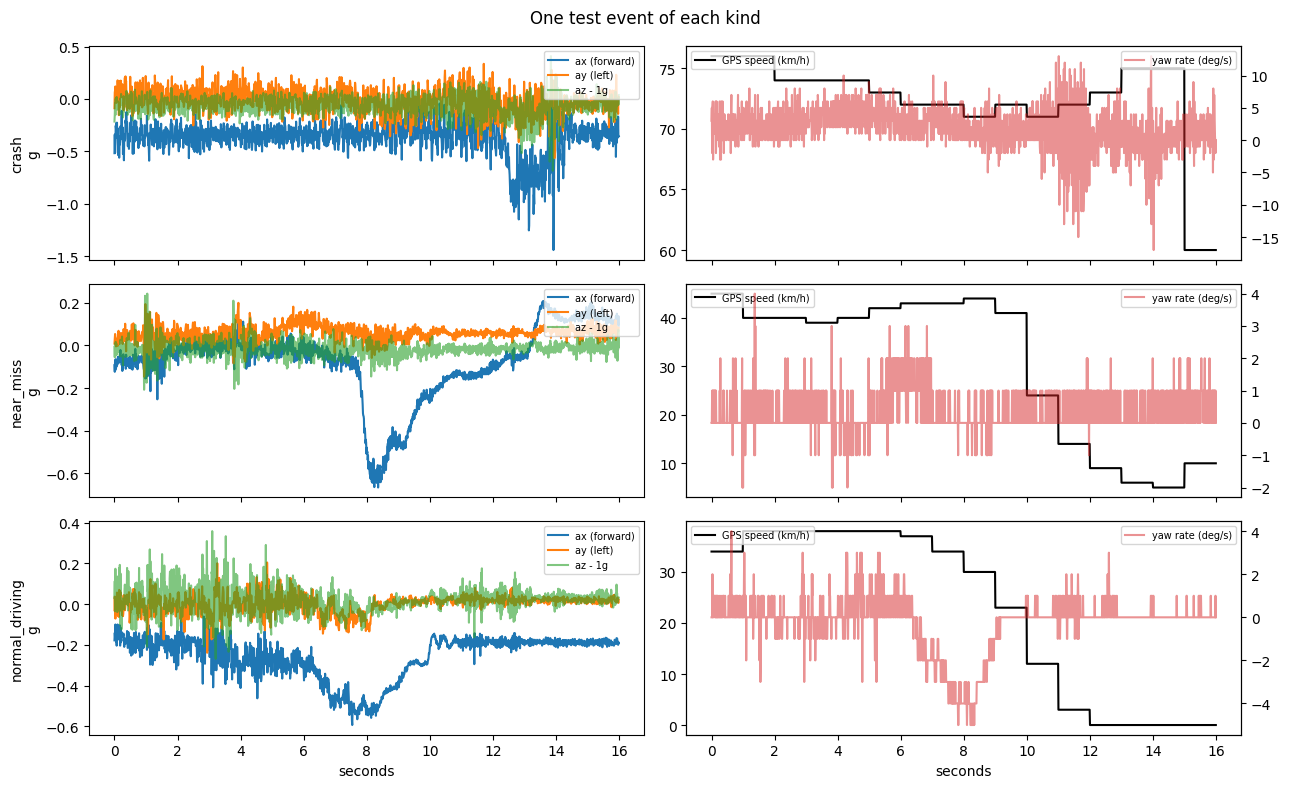

In [6]:
counts = pd.concat({s: data[s][2]["kind"].value_counts() for s in data}, axis=1).fillna(0).astype(int)
counts.loc["share crash"] = (counts.loc["crash"] / counts.sum()).round(3)
print(counts.to_string())
print("\nVehicle size (test):", Mte["vehiclesize"].value_counts().to_dict())

fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex=True)
t = np.arange(T_LEN) / 100
for row, kind in enumerate(["crash", "near_miss", "normal_driving"]):
    i = Mte.index[Mte["kind"] == kind][0]
    c = Cte[i].astype(np.float32)
    axes[row, 0].plot(t, c[0], label="ax (forward)"); axes[row, 0].plot(t, c[1], label="ay (left)")
    axes[row, 0].plot(t, c[2], label="az - 1g", alpha=0.6)
    axes[row, 0].set_ylabel(f"{kind}\ng"); axes[row, 0].legend(fontsize=7, loc="upper right")
    axes[row, 1].plot(t, c[6], color="k", label="GPS speed (km/h)")
    ax2 = axes[row, 1].twinx(); ax2.plot(t, c[5], color="tab:red", alpha=0.5, label="yaw rate (deg/s)")
    axes[row, 1].legend(fontsize=7, loc="upper left"); ax2.legend(fontsize=7, loc="upper right")
axes[-1, 0].set_xlabel("seconds"); axes[-1, 1].set_xlabel("seconds")
plt.suptitle("One test event of each kind"); plt.tight_layout(); plt.show()

## 5 · Baseline: physics rules, no training

- **Peak g** (the paper's baseline): the highest sideways/forward acceleration in the window. Higher = more likely a crash.
- **Event-recorder rule** (US rule 49 CFR 563, used in every car's airbag module): the largest speed change in any 150 ms. A car "records a crash" at **8 km/h**.

**AP** (average precision, the paper's metric) = area under the precision-recall curve. 1.0 = perfect; a random score gets the share of crashes (~0.16). The paper reports **0.896** for the peak-g rule on this test set.

In [7]:
def recall_at_precision(y, p, target):
    prec, rec, _ = precision_recall_curve(y, p)
    ok = prec >= target
    return rec[ok].max() if ok.any() else 0.0

def scores(y, p):
    return {"AP": average_precision_score(y, p), "ROC AUC": roc_auc_score(y, p),
            "recall @ 95% precision": recall_at_precision(y, p, 0.95),
            "recall @ 99% precision": recall_at_precision(y, p, 0.99)}

yte, yva, ytr = Mte["y"].values, Mva["y"].values, Mtr["y"].values
test_probs = {
    "Rule · peak g": Xte["xy_peak_g"].values,
    "Rule · ΔV in 150 ms": Xte["dv150_kmh"].values,
}
for name, p in test_probs.items():
    print(f"{name:<22}", {k: round(v, 3) for k, v in scores(yte, p).items()})

fired = Xte["dv150_kmh"].values >= 8
print(f"\nEvent-recorder trigger (ΔV ≥ 8 km/h in 150 ms): catches {fired[yte == 1].mean():.1%} of crashes, "
      f"fires on {fired[yte == 0].mean():.1%} of non-crashes")
print("Most fleet crashes in VZCrash are low-speed contacts, far below what an airbag module records.")

Rule · peak g          {'AP': np.float64(0.896), 'ROC AUC': np.float64(0.979), 'recall @ 95% precision': np.float64(0.356), 'recall @ 99% precision': np.float64(0.0)}
Rule · ΔV in 150 ms    {'AP': np.float64(0.843), 'ROC AUC': np.float64(0.956), 'recall @ 95% precision': np.float64(0.52), 'recall @ 99% precision': np.float64(0.0)}

Event-recorder trigger (ΔV ≥ 8 km/h in 150 ms): catches 51.3% of crashes, fires on 0.6% of non-crashes
Most fleet crashes in VZCrash are low-speed contacts, far below what an airbag module records.


## 6 · AI model 1: LightGBM on the features

Same kind of model as M1 and M3: hundreds of small decision trees on the 43 features. Runs on any CPU in a few milliseconds per event, so it could run **inside** the blackbox. We stop adding trees when the validation AP stops improving.

In [8]:
LGB_PARAMS = dict(
    n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=SEED, verbose=-1,
)
lgbm = lgb.LGBMClassifier(**LGB_PARAMS)
lgbm.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="average_precision",
         callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)])
print(f"Stopped at {lgbm.best_iteration_} trees (validation AP {lgbm.best_score_['valid_0']['average_precision']:.4f})")

val_probs = {"LightGBM": lgbm.predict_proba(Xva)[:, 1]}
test_probs["LightGBM"] = lgbm.predict_proba(Xte)[:, 1]
print("Test:", {k: round(v, 4) for k, v in scores(yte, test_probs["LightGBM"]).items()})

imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False)
print("\nTop 15 inputs (share of the model's decisions):")
print((imp.head(15) * 100).round(1).astype(str).add(" %").to_string())

[200]	valid_0's average_precision: 0.981207	valid_0's binary_logloss: 0.0552514
[400]	valid_0's average_precision: 0.982406	valid_0's binary_logloss: 0.0533499
Stopped at 395 trees (validation AP 0.9824)
Test: {'AP': np.float64(0.9828), 'ROC AUC': np.float64(0.9963), 'recall @ 95% precision': np.float64(0.9041), 'recall @ 99% precision': np.float64(0.7114)}

Top 15 inputs (share of the model's decisions):
xy_peak_g          65.4 %
dv150_kmh           5.5 %
a3_peak_g           3.7 %
xy_over_05g_ms      2.2 %
dv500_kmh           1.9 %
xy_mean_g           1.6 %
ay_absmax_g         1.5 %
xy_over_1g_ms       1.3 %
peak_time_s         1.2 %
az_max_g            1.0 %
speed_max_decel     1.0 %
az_std_g            1.0 %
xy_std_pre2s        0.8 %
ax_min_g            0.7 %
gyro_mean           0.7 %


## 7 · AI model 2: CNN-RNN on the raw signals (GPU)

The paper's best model family (CNN-RNN, AP 0.976). Ours is smaller (~0.3 M parameters):
- 3 convolution layers read short patterns (a shock, a bounce) and shrink 1600 steps to 200
- a bidirectional GRU reads those 200 steps in order: *was the car moving, then a shock, then still?*
- max + mean pooling, then one output: the crash probability

**Training tricks:** each batch is shifted by up to ±1 s (crashes don't always sit at the same moment) and rotated by up to ±15° around the vertical axis (the paper says device alignment is sometimes off). Mixed precision for speed. We keep the epoch with the best validation AP.

In [9]:
class CrashNet(nn.Module):
    def __init__(self, ch=7, width=128):
        super().__init__()
        def block(i, o, k):
            return nn.Sequential(nn.Conv1d(i, o, k, stride=2, padding=k // 2), nn.BatchNorm1d(o), nn.GELU())
        self.conv = nn.Sequential(block(ch, 64, 7), block(64, 96, 5), block(96, width, 5))
        self.gru = nn.GRU(width, width, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(4 * width, 1))

    def forward(self, x):                      # x: (B, 7, T), standardized
        h = self.conv(x).transpose(1, 2)       # (B, T/8, width)
        h, _ = self.gru(h)                     # (B, T/8, 2*width)
        h = torch.cat([h.max(1).values, h.mean(1)], dim=1)
        return self.head(h).squeeze(1)         # logit

CH_LIMITS = np.array([bb.ACC_LIMIT_G] * 3 + [bb.GYRO_LIMIT_DPS] * 3 + [bb.SPEED_LIMIT_KMH], np.float32)[None, :, None]

def clean_channels(C, chunk=4096):
    """In place: replace NaN/inf and clip every channel to its physical limit. Returns how many values were fixed."""
    fixed = 0
    for i in range(0, len(C), chunk):
        c = C[i : i + chunk]
        bad = ~np.isfinite(c) | (np.abs(c.astype(np.float32)) > CH_LIMITS)
        fixed += int(bad.sum())
        np.nan_to_num(c, copy=False, nan=0.0, posinf=6e4, neginf=-6e4)
        np.clip(c, -CH_LIMITS, CH_LIMITS, out=c)
    return fixed

for name, C in [("train", Ctr), ("validation", Cva), ("test", Cte)]:
    print(f"{name}: fixed {clean_channels(C):,} out-of-range values")

# Per-channel scale, from a sample of the training set
sample = Ctr[np.random.default_rng(SEED).choice(len(Ctr), min(len(Ctr), 5000), replace=False)].astype(np.float64)
CH_MEAN = sample.mean(axis=(0, 2)).astype(np.float32)
CH_STD = (sample.std(axis=(0, 2)) + 1e-3).astype(np.float32)
assert np.isfinite(CH_MEAN).all() and np.isfinite(CH_STD).all(), "channel scaling is not finite"
print("channel mean:", CH_MEAN.round(3), "\nchannel std: ", CH_STD.round(3))
mean_t = torch.tensor(CH_MEAN, device=DEVICE)[None, :, None]
std_t = torch.tensor(CH_STD, device=DEVICE)[None, :, None]

def augment(x):
    """x: raw-unit batch (B, 7, T) on the device. Random ±1 s shift and ±15° yaw rotation."""
    B, _, T = x.shape
    shift = int(torch.randint(0, 201, (1,)))
    x = F.pad(x, (100, 100), mode="replicate")[..., shift : shift + T]
    a = (torch.rand(B, 1, device=x.device) - 0.5) * np.radians(30)
    c, s = torch.cos(a), torch.sin(a)
    ax, ay, gx, gy = x[:, 0], x[:, 1], x[:, 3], x[:, 4]
    x = x.clone()
    x[:, 0], x[:, 1] = c * ax - s * ay, s * ax + c * ay
    x[:, 3], x[:, 4] = c * gx - s * gy, s * gx + c * gy
    return x

@torch.no_grad()
def predict_cnn(model, C, batch=1024):
    model.eval()
    out = []
    for i in range(0, len(C), batch):
        x = torch.from_numpy(C[i : i + batch]).to(DEVICE).float()
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            out.append(torch.sigmoid(model((x - mean_t) / std_t)).float().cpu().numpy())
    p = np.concatenate(out)
    if not np.isfinite(p).all():
        print(f"  ⚠ {(~np.isfinite(p)).sum()} non-finite predictions, set to 0.5")
        p = np.nan_to_num(p, nan=0.5, posinf=1.0, neginf=0.0)
    return p

EPOCHS, BATCH, PATIENCE = (2, 64, 2) if QUICK else (20, 256, 5)
model = CrashNet().to(DEVICE)
print(f"CrashNet: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters")
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
steps = EPOCHS * int(np.ceil(len(Ctr) / BATCH))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=steps, pct_start=0.15)
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
ytr_t = torch.from_numpy(ytr).float()

best_ap, best_state, bad = -1, None, 0
for epoch in range(EPOCHS):
    model.train()
    t0, losses, skipped = time.time(), [], 0
    for idx in torch.randperm(len(Ctr)).split(BATCH):
        idx = np.sort(idx.numpy())
        x = augment(torch.from_numpy(Ctr[idx]).to(DEVICE, non_blocking=True).float())
        y = ytr_t[idx].to(DEVICE)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            loss = F.binary_cross_entropy_with_logits(model((x - mean_t) / std_t).float(), y)
        if not torch.isfinite(loss):
            skipped += 1
            sched.step()
            continue
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
    ap = average_precision_score(yva, predict_cnn(model, Cva))
    print(f"epoch {epoch + 1:>2}  loss {np.mean(losses):.4f}  validation AP {ap:.4f}  ({time.time() - t0:.0f} s)"
          + (f"  ⚠ skipped {skipped} non-finite batches" if skipped else ""))
    if ap > best_ap:
        best_ap, bad = ap, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= PATIENCE:
            print("No improvement: stopping.")
            break

model.load_state_dict(best_state)
val_probs["CNN-RNN"] = predict_cnn(model, Cva)
test_probs["CNN-RNN"] = predict_cnn(model, Cte)
print(f"Best validation AP {best_ap:.4f}")
print("Test:", {k: round(v, 4) for k, v in scores(yte, test_probs["CNN-RNN"]).items()})

train: fixed 0 out-of-range values
validation: fixed 0 out-of-range values
test: fixed 0 out-of-range values
channel mean: [-5.3000e-02  2.9000e-02 -4.0000e-02 -4.2000e-02  1.5400e-01  2.8000e-02
  4.7083e+01] 
channel std:  [ 0.272  0.254  0.245 18.831  8.436 10.988 34.034]
CrashNet: 0.29 M parameters
epoch  1  loss 0.1752  validation AP 0.9583  (18 s)
epoch  2  loss 0.0740  validation AP 0.9768  (16 s)
epoch  3  loss 0.0645  validation AP 0.9804  (16 s)
epoch  4  loss 0.0605  validation AP 0.9808  (16 s)
epoch  5  loss 0.0559  validation AP 0.9822  (16 s)
epoch  6  loss 0.0537  validation AP 0.9823  (16 s)
epoch  7  loss 0.0526  validation AP 0.9844  (16 s)
epoch  8  loss 0.0491  validation AP 0.9862  (16 s)
epoch  9  loss 0.0475  validation AP 0.9831  (16 s)
epoch 10  loss 0.0454  validation AP 0.9853  (16 s)
epoch 11  loss 0.0429  validation AP 0.9862  (16 s)
epoch 12  loss 0.0409  validation AP 0.9881  (16 s)
epoch 13  loss 0.0381  validation AP 0.9873  (16 s)
epoch 14  loss 0.035

## 8 · Compare them

The **ensemble** is the average of the two AI models' probabilities. We pick the model to deploy on the **validation** set (best AP), so the test stays honest.

For reference, the paper's test APs: peak-g rule 0.896 · CNN-RNN 0.976 · CNN-Transformer 0.975 · Chronos-Bolt 0.966.

                         AP  ROC AUC  recall @ 95% precision  recall @ 99% precision
Rule · peak g        0.8962   0.9794                  0.3556                  0.0000
Rule · ΔV in 150 ms  0.8434   0.9557                  0.5195                  0.0000
LightGBM             0.9828   0.9963                  0.9041                  0.7114
CNN-RNN              0.9898   0.9979                  0.9564                  0.7600
Ensemble             0.9901   0.9979                  0.9569                  0.8072

Deployed model (best validation AP): Ensemble


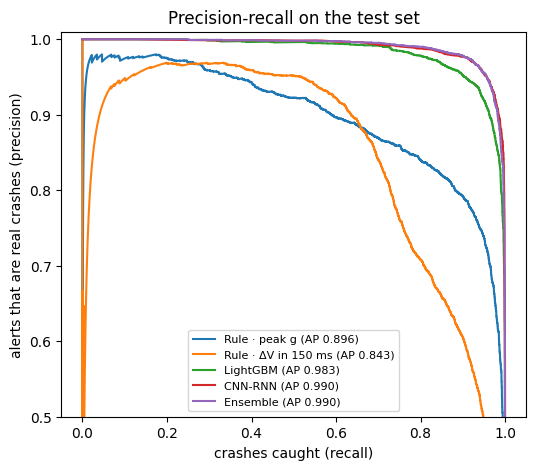

In [10]:
val_probs["Ensemble"] = (val_probs["LightGBM"] + val_probs["CNN-RNN"]) / 2
test_probs["Ensemble"] = (test_probs["LightGBM"] + test_probs["CNN-RNN"]) / 2

results = pd.DataFrame({name: scores(yte, p) for name, p in test_probs.items()}).T
print(results.round(4).to_string())

DEPLOY = max(val_probs, key=lambda k: average_precision_score(yva, val_probs[k]))
print(f"\nDeployed model (best validation AP): {DEPLOY}")

fig, ax = plt.subplots(figsize=(6, 5))
for name, p in test_probs.items():
    prec, rec, _ = precision_recall_curve(yte, p)
    ax.plot(rec, prec, label=f"{name} (AP {average_precision_score(yte, p):.3f})")
ax.set_xlabel("crashes caught (recall)"); ax.set_ylabel("alerts that are real crashes (precision)")
ax.set_ylim(0.5, 1.01); ax.legend(fontsize=8); ax.set_title("Precision-recall on the test set")
plt.show()

## 9 · From a score to alert levels, and what it means on real roads

The platform needs levels, not a probability. Cuts are chosen on **validation**:

| Level | Rule | Platform action (S4 ladder) |
|---|---|---|
| **crash** | precision ≥ 99 % | red: alert services now, warn cars behind |
| **likely** | catches 95 % of crashes | yellow: start the 30 s "Are you OK?" countdown, pre-alert the dispatcher |
| **possible** | catches 99 % of crashes | ask the driver and nearby witnesses quietly |
| **none** | below | log only |

**Real roads are different from the test set.** The test set is ~16 % crashes. In the paper's real-world check, only **143 of 735,000** triggered events were crashes (0.02 %). The same false-alarm rate then produces many more false alarms per real crash, so we also report **false alarms per 100,000 triggered events** and the precision we would get at that real-world crash rate. (The test negatives include deliberately hard cases, so this is on the pessimistic side.)

In [11]:
def threshold_for_recall(y, p, recall):
    return float(np.quantile(p[y == 1], 1 - recall))

def threshold_for_precision(y, p, target):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(prec[:-1] >= target)[0]
    return float(thr[ok[0]]) if len(ok) else float(p.max())

pv = val_probs[DEPLOY]
CUTS = {
    "possible": threshold_for_recall(yva, pv, 0.99),
    "likely":   threshold_for_recall(yva, pv, 0.95),
    "crash":    max(threshold_for_precision(yva, pv, 0.99), threshold_for_recall(yva, pv, 0.95)),
}
LEVELS = ["none", "possible", "likely", "crash"]

def to_level(p):
    return np.select([p >= CUTS["crash"], p >= CUTS["likely"], p >= CUTS["possible"]],
                     ["crash", "likely", "possible"], default="none")

REAL_PRIOR = 143 / 735_000
pt = test_probs[DEPLOY]
rows = []
for name, thr in CUTS.items():
    flag = pt >= thr
    rec, fpr = flag[yte == 1].mean(), flag[yte == 0].mean()
    rows.append({"level ≥": name, "threshold": thr, "crashes caught": rec, "non-crashes flagged": fpr,
                 "test precision": yte[flag].mean() if flag.any() else np.nan,
                 "false alarms / 100k events": fpr * 1e5 * (1 - REAL_PRIOR),
                 "precision on real roads": rec * REAL_PRIOR / (rec * REAL_PRIOR + fpr * (1 - REAL_PRIOR) + 1e-12)})
ops = pd.DataFrame(rows).set_index("level ≥")
print(f"{DEPLOY} on the test set:")
print(ops.round(4).to_string())

# Same view for the rule, at the paper's real-world operating point (75 % recall): paper = 780 false alarms in 735k
pr = test_probs["Rule · peak g"]
thr75 = threshold_for_recall(yte, pr, 0.75)
fa_rule = (pr[yte == 0] >= thr75).mean() * 1e5
fa_ai = (pt[yte == 0] >= threshold_for_recall(yte, pt, 0.75)).mean() * 1e5
print(f"\nAt 75 % recall: peak-g rule ≈ {fa_rule:.0f} false alarms per 100k events, {DEPLOY} ≈ {fa_ai:.0f}. "
      f"(Paper, real roads: rule 106 per 100k, best AI 1.4 per 100k.)")

print("\nWhich non-crashes fool it at the 'likely' cut:")
flag = pt >= CUTS["likely"]
print(Mte.assign(flag=flag)[yte == 0].groupby("kind")["flag"].mean().map("{:.2%}".format).to_string())
print("\nAP by vehicle size (Light ≈ passenger cars, our main target):")
print(Mte.assign(p=pt).groupby("vehiclesize").apply(
    lambda g: pd.Series({"events": len(g), "crashes": g.y.sum(),
                         "AP": average_precision_score(g.y, g.p) if 0 < g.y.sum() < len(g) else np.nan})).round(3).to_string())

Ensemble on the test set:
          threshold  crashes caught  non-crashes flagged  test precision  false alarms / 100k events  precision on real roads
level ≥                                                                                                                      
possible     0.0886          0.9922               0.0392          0.8427                   3918.4476                   0.0049
likely       0.5726          0.9498               0.0093          0.9557                    932.0093                   0.0194
crash        0.9585          0.7228               0.0010          0.9938                     95.2052                   0.1287

At 75 % recall: peak-g rule ≈ 2596 false alarms per 100k events, Ensemble ≈ 125. (Paper, real roads: rule 106 per 100k, best AI 1.4 per 100k.)

Which non-crashes fool it at the 'likely' cut:
kind
near_miss         1.71%
normal_driving    0.76%

AP by vehicle size (Light ≈ passenger cars, our main target):
             events  crashes     AP


## 10 · From a detected crash to M3's inputs

When M2 says *crash*, the blackbox computes the 4 things M3 needs from the same recording (`bb.crash_summary`):
- **ΔV**: acceleration integrated over the crash pulse, minus the level before (braking), in km/h
- **impact direction**: where the force comes from, clockwise from the front (0 front, 90 right, 180 rear, 270 left = driver's door in Algeria)
- **rollover**: rolled past 90°, or ended upside down
- **multiple impacts**: a second peak over 1.5 g at least 0.5 s away from the first

**Reality check:** M3 was trained on NASS-CDS/CISS, mostly tow-away crashes (median ΔV ≈ 20–25 km/h). VZCrash is mostly minor fleet contacts, so expect much lower ΔV here. That is fine: low ΔV should give a *low* severity.

3,000 test crashes flagged 'crash':
       dv_kmh  pdof_deg  rollover  multi_impact  peak_g  speed_before_kmh
count  3000.0    3000.0    3000.0        3000.0  3000.0            3000.0
mean      8.8     194.6       0.1           0.5     4.1              71.9
std       4.9     136.6       0.3           0.5     1.1              31.0
min       0.3       0.0       0.0           0.0     1.3               0.0
50%       8.3     202.0       0.0           0.0     4.1              73.0
90%      14.9     355.0       0.0           1.0     5.5             111.0
99%      22.8     360.0       1.0           1.0     6.3             131.0
max      36.8     360.0       1.0           1.0     7.1             159.0


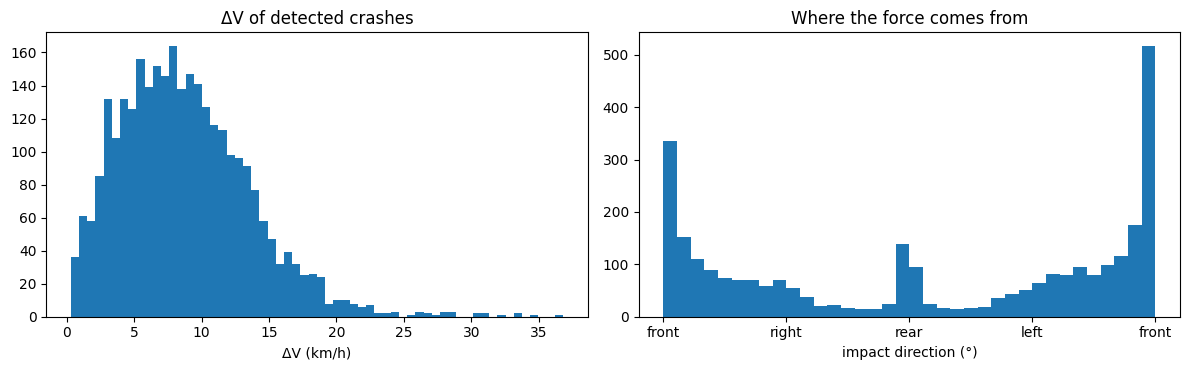

In [12]:
def summary_from_channels(c):
    c = c.astype(np.float32)
    acc = np.stack([c[0], c[1], c[2] + 1], axis=1)
    gyro = c[3:6].T
    speed = c[6, ::100]
    return bb.crash_summary(acc, gyro, speed)

crash_idx = Mte.index[(Mte["y"] == 1) & (to_level(pt) == "crash")]
summ = pd.DataFrame([summary_from_channels(Cte[i]) for i in crash_idx[:3000]])
print(f"{len(summ):,} test crashes flagged 'crash':")
print(summ.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(summ["dv_kmh"].clip(upper=60), bins=60); axes[0].set_xlabel("ΔV (km/h)"); axes[0].set_title("ΔV of detected crashes")
axes[1].hist(summ["pdof_deg"], bins=36, range=(0, 360)); axes[1].set_xlabel("impact direction (°)")
axes[1].set_xticks([0, 90, 180, 270, 360]); axes[1].set_xticklabels(["front", "right", "rear", "left", "front"])
axes[1].set_title("Where the force comes from")
plt.tight_layout(); plt.show()

## 11 · Save everything

For the backend: both models, the shared signal code, the config (features, channel scaling, cuts, scores). For the blackbox simulator: a few real events to replay.

In [13]:
lgbm.booster_.save_model(OUT / "m2_lgbm.txt", num_iteration=lgbm.best_iteration_)
torch.save({"state_dict": model.state_dict(), "ch_mean": CH_MEAN, "ch_std": CH_STD}, OUT / "m2_cnn.pt")

onnx_ok = False
try:
    model.eval().cpu()
    dummy = torch.zeros(1, 7, T_LEN)
    torch.onnx.export(model, dummy, OUT / "m2_cnn.onnx", input_names=["x"], output_names=["logit"],
                      dynamic_axes={"x": {0: "batch"}, "logit": {0: "batch"}}, opset_version=17, dynamo=False)
    onnx_ok = True
    print("ONNX export ok (input = standardized channels: (x - ch_mean) / ch_std)")
except Exception as e:
    print(f"ONNX export skipped: {e}")
finally:
    model.to(DEVICE)

config = {
    "deploy": DEPLOY,
    "models": {"lightgbm": "m2_lgbm.txt", "cnn_rnn": "m2_cnn.pt", "cnn_rnn_onnx": "m2_cnn.onnx" if onnx_ok else None},
    "ensemble": "mean of the LightGBM and CNN-RNN probabilities",
    "features": FEATURES,
    "channels": ["ax_g", "ay_g", "az_minus_1g", "gx_dps", "gy_dps", "gz_dps", "speed_kmh"],
    "ch_mean": CH_MEAN.round(5).tolist(), "ch_std": CH_STD.round(5).tolist(),
    "window": {"hz": 100, "samples": T_LEN, "gps_hz": 1, "axes": "x forward, y left, z up (+1 g at rest)"},
    "cuts": CUTS, "levels": LEVELS,
    "target": "crash vs (near-miss + normal driving), VZCrash 2026, vehicle-disjoint train/validation/test",
    "test_scores": results.round(4).to_dict(orient="index"),
    "operating_points": ops.round(5).reset_index().to_dict(orient="records"),
    "real_world_prior": REAL_PRIOR,
}
(OUT / "m2_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False, default=float))
(OUT / "m2_blackbox.py").write_text(Path("m2_blackbox.py").read_text())

# A few real events for the blackbox simulator (CC BY-NC: hackathon use only)
rng = np.random.default_rng(SEED)
pick = {kind: rng.choice(Mte.index[Mte["kind"] == kind], min(8, (Mte["kind"] == kind).sum()), replace=False)
        for kind in LABELS.values()}
idx = np.concatenate(list(pick.values()))
np.savez_compressed(OUT / "m2_sample_events.npz", channels=Cte[idx], kind=Mte.loc[idx, "kind"].values,
                    event_id=Mte.loc[idx, "event_id"].values, score=pt[idx])

import shutil
shutil.make_archive(str(OUT), "zip", OUT)
for f in sorted(OUT.iterdir()):
    print(f"  {f.name:<24} {f.stat().st_size / 1024:>8.0f} KB")
print(f"\nDownload: {OUT}.zip (Output panel on the right)")

ONNX export ok (input = standardized channels: (x - ch_mean) / ch_std)
  m2_blackbox.py                  9 KB
  m2_cnn.onnx                  1156 KB
  m2_cnn.pt                    1162 KB
  m2_config.json                  4 KB
  m2_lgbm.txt                  2667 KB
  m2_sample_events.npz          213 KB

Download: /kaggle/working/m2_models.zip (Output panel on the right)


## 12 · Try it on single events

This is what the backend does when a blackbox uploads a 16 s window: features → model → level, and for a crash, the M3 inputs.

In [14]:
def m2_predict(acc, gyro, speed):
    """acc, gyro: (T, 3); speed: (16,). Returns the M2 result the platform stores."""
    _, X = bb.window_features(acc[None], gyro[None], np.asarray(speed, np.float32)[None])
    p_lgbm = lgbm.predict_proba(pd.DataFrame(X, columns=FEATURES))[:, 1]
    p_cnn = predict_cnn(model, bb.to_channels(acc[None], gyro[None], np.asarray(speed, np.float32)[None]))
    p = {"LightGBM": p_lgbm, "CNN-RNN": p_cnn, "Ensemble": (p_lgbm + p_cnn) / 2}[DEPLOY][0]
    out = {"p_crash": round(float(p), 4), "level": str(to_level(np.array([p]))[0])}
    if out["level"] in ("likely", "crash"):
        out["m3_inputs"] = bb.crash_summary(acc, gyro, speed)
    return out

for kind, ids in pick.items():
    for i in ids[:2]:
        c = Cte[i].astype(np.float32)
        acc, gyro, speed = np.stack([c[0], c[1], c[2] + 1], 1), c[3:6].T, c[6, ::100]
        print(f"{kind:<15} {m2_predict(acc, gyro, speed)}")

crash           {'p_crash': 0.9888, 'level': 'crash', 'm3_inputs': {'dv_kmh': 2.7, 'pdof_deg': 259, 'rollover': 0, 'multi_impact': 0, 'peak_g': 4.41, 'speed_before_kmh': 75.0}}
crash           {'p_crash': 0.9849, 'level': 'crash', 'm3_inputs': {'dv_kmh': 6.7, 'pdof_deg': 303, 'rollover': 0, 'multi_impact': 1, 'peak_g': 4.15, 'speed_before_kmh': 86.0}}
near_miss       {'p_crash': 0.0, 'level': 'none'}
near_miss       {'p_crash': 0.0001, 'level': 'none'}
normal_driving  {'p_crash': 0.0, 'level': 'none'}
normal_driving  {'p_crash': 0.0, 'level': 'none'}


## Results to copy back

Copy everything this cell prints and paste it to Claude: it updates the team plan from it.

In [15]:
flag_likely = pt >= CUTS["likely"]
summary = {
    "events": {s: {"total": int(len(m)), "crashes": int(m["y"].sum())} for s, (_, _, m) in data.items()},
    "train_fraction": TRAIN_FRACTION,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
    "deploy": DEPLOY,
    "lightgbm_trees": int(lgbm.best_iteration_),
    "cnn_best_val_ap": round(float(best_ap), 4),
    "test": results.round(4).to_dict(orient="index"),
    "edr_8kmh_rule": {"crashes_caught": round(float(fired[yte == 1].mean()), 4),
                      "non_crashes_flagged": round(float(fired[yte == 0].mean()), 4)},
    "cuts": {k: round(v, 4) for k, v in CUTS.items()},
    "operating_points": ops.round(5).reset_index().to_dict(orient="records"),
    "false_alarms_per_100k_at_75pct_recall": {"rule_peak_g": round(float(fa_rule), 1), DEPLOY: round(float(fa_ai), 1)},
    "flagged_likely_by_kind": Mte.assign(f=flag_likely)[yte == 0].groupby("kind")["f"].mean().round(4).to_dict(),
    "ap_by_vehicle_size": {str(k): round(float(average_precision_score(g.y, g.p)), 4)
                           for k, g in Mte.assign(p=pt).groupby("vehiclesize") if 0 < g.y.sum() < len(g)},
    "top_features": (imp.head(8) * 100).round(1).to_dict(),
    "crash_summary": {"n": int(len(summ)), "dv_kmh_median": float(summ["dv_kmh"].median()),
                      "dv_kmh_p90": float(summ["dv_kmh"].quantile(0.9)),
                      "rollover_share": float(summ["rollover"].mean()), "multi_impact_share": float(summ["multi_impact"].mean())},
}
print("=== M2 RESULTS (copy from here) ===")
print(json.dumps(summary, indent=1, default=float))
print("=== END ===")

=== M2 RESULTS (copy from here) ===
{
 "events": {
  "train": {
   "total": 137954,
   "crashes": 22603
  },
  "validation": {
   "total": 27175,
   "crashes": 4255
  },
  "test": {
   "total": 24174,
   "crashes": 4221
  }
 },
 "train_fraction": 1.0,
 "gpu": "Tesla T4",
 "deploy": "Ensemble",
 "lightgbm_trees": 395,
 "cnn_best_val_ap": 0.9884,
 "test": {
  "Rule \u00b7 peak g": {
   "AP": 0.8962,
   "ROC AUC": 0.9794,
   "recall @ 95% precision": 0.3556,
   "recall @ 99% precision": 0.0
  },
  "Rule \u00b7 \u0394V in 150 ms": {
   "AP": 0.8434,
   "ROC AUC": 0.9557,
   "recall @ 95% precision": 0.5195,
   "recall @ 99% precision": 0.0
  },
  "LightGBM": {
   "AP": 0.9828,
   "ROC AUC": 0.9963,
   "recall @ 95% precision": 0.9041,
   "recall @ 99% precision": 0.7114
  },
  "CNN-RNN": {
   "AP": 0.9898,
   "ROC AUC": 0.9979,
   "recall @ 95% precision": 0.9564,
   "recall @ 99% precision": 0.76
  },
  "Ensemble": {
   "AP": 0.9901,
   "ROC AUC": 0.9979,
   "recall @ 95% precision": 0.95

## Notes for the pitch

- Trained on **real blackbox recordings**: ~189,000 events from 73,000 vehicles, labeled by 3 experts with dashcam video, tested on vehicles the model never saw.
- The physics rule (what airbag modules and eCall do) is the baseline; the AI is measured against it on the same data. The number that matters on real roads is **false alarms per real crash**, and that is where the AI wins.
- The same 16 s recording gives M3 its inputs (ΔV, direction, rollover, multiple impacts), so one device feeds detection *and* severity.
- Limits to say honestly: commercial vehicles (vans, trucks), mostly minor crashes; Algerian cars and roads will need recalibration on our own blackbox data. Crash confidence on the platform still combines M2 with the phone, the "Are you OK?" check-in and witnesses.